- Objective: Delve into the dynamics of product pricing on Amazon UK to uncover insights that can inform business strategies and decision-making.
- Dataset: This lab utilizes the Amazon UK product dataset 

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline

# Load the dataset
file_path = r"C:\Users\cpall\Desktop\ironhack\amz_uk_price_prediction_dataset.csv"

# Read the CSV file into a DataFrame
df = pd.read_csv(file_path)

# Display basic information about the dataframe
df.info()
df.shape

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB


(2443651, 9)

In [12]:
# Number of unique categories
num_categories = df['category'].nunique()
print("Number of unique product categories:", num_categories)


Number of unique product categories: 296


- The categories Grocery, Smart Home Security & Lighting, and Health & Personal Care stand out because they show the highest prevalence of Best-Seller products among all categories.
- Specifically, 5.81%, 5.77%, and 5.77% of the products in these categories are marked as Best-Sellers.
- This means that, relative to their total number of listings, these categories have a higher concentration of Best-Seller items compared to the rest of the product categories.

In [ ]:
# Part 1: Analyzing Best-Seller Trends Across Product Categories
# Objective: Understand the relationship between product categories and their best-seller status.

# Crosstab Analysis:
# Create a crosstab between the product category and the isBestSeller status.
# Are there categories where being a best-seller is more prevalent?
# Hint: one option is to calculate the proportion of best-sellers for each category
# and then sort the categories based on this proportion in descending order.

# crosstab_result = pd.crosstab(df['category'], df['isBestSeller'])

# Absolute frequencies (counts)
counts = pd.crosstab(df['category'], df['isBestSeller'])

# Relative frequencies (%) per row
rel_freq = pd.crosstab(df['category'], df['isBestSeller'], normalize='index') * 100
rel_freq = rel_freq.round(2)

# Rename columns for clarity
counts.columns = ['Not BestSeller', 'BestSeller']
rel_freq.columns = ['Not BestSeller (%)', 'BestSeller (%)']

# Combine both tables
crosstab_result = pd.concat([counts, rel_freq], axis=1)

# Sort by highest percentage of BestSeller
crosstab_result = crosstab_result.sort_values(by='BestSeller (%)', ascending=False)

# Display final table
crosstab_result


,Not BestSeller,BestSeller,Not BestSeller (%),BestSeller (%)
category,,,,
Grocery,9008,556,94.19,5.81
Smart Home Security & Lighting,98,6,94.23,5.77
Health & Personal Care,9017,552,94.23,5.77
Mobile Phone Accessories,248,11,95.75,4.25
Power & Hand Tools,8353,306,96.47,3.53
...,...,...,...,...
CPUs,249,0,100.00,0.00
"CD, Disc & Tape Players",8798,0,100.00,0.00
Blank Media Cases & Wallets,243,0,100.00,0.00


- The null hypothesis of the Chi-square test is that the two categorical variables are independent. Given the extremely low ( p )-value, we reject the null hypothesis. This implies that there's a significant association between the two categorical variables category and isBestSeller in the dataset.
- The Cramér's V value of 0.122 suggests a weak association between the two variables. Though statistically significant, the strength of this relationship is not very strong in practical terms.

In [14]:
# Statistical Tests:

# Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
from scipy.stats import chi2_contingency

# Run Chi-Square test of independence
# Use the crosstab with absolute frequencies (counts)
chi2_statistic, chi2_p_value, dof, expected = chi2_contingency(counts)

chi2_statistic, chi2_p_value
print(f"Chi-square statistic: {chi2_statistic:.4f}")
print(f"P-value: {chi2_p_value:.4e}")
print(f"Degrees of freedom: {dof}")
print("Expected frequencies:")
print(expected)

# Compute Cramér's V to understand the strength of association between best-seller status and category.
from scipy.stats.contingency import association

# Computing the association between variables in the crosstab with absolute frequencies (counts) using the "cramer" method
cramers_v = association(counts, method="cramer")
print(f"Cramer coefficient of association: {cramers_v:.3f}")


Chi-square statistic: 36540.2027
P-value: 0.0000e+00
Degrees of freedom: 295
Expected frequencies:
[[2.47190130e+02 8.09870149e-01]
 [4.05371878e+03 1.32812173e+01]
 [2.49183599e+02 8.16401360e-01]
 [1.69145827e+03 5.54173243e+00]
 [2.53170536e+02 8.29463782e-01]
 [8.50214439e+03 2.78556144e+01]
 [1.06650580e+02 3.49419782e-01]
 [2.57157474e+02 8.42526204e-01]
 [9.51781673e+03 3.11832664e+01]
 [1.50008526e+04 4.91473619e+01]
 [9.32544700e+03 3.05530045e+01]
 [2.38219520e+02 7.80479700e-01]
 [3.22941944e+03 1.05805616e+01]
 [9.44704859e+03 3.09514084e+01]
 [6.68808779e+03 2.19122125e+01]
 [5.26275760e+02 1.72423967e+00]
 [1.90296531e+04 6.23469391e+01]
 [2.77191835e+03 9.08164873e+00]
 [2.53170536e+02 8.29463782e-01]
 [4.04674164e+02 1.32583581e+00]
 [1.92489346e+04 6.30653723e+01]
 [3.10482764e+03 1.01723609e+01]
 [2.04330551e+02 6.69449115e-01]
 [6.28839730e+03 2.06027047e+01]
 [5.23385231e+03 1.71476942e+01]
 [9.52180367e+03 3.11963288e+01]
 [2.48186864e+02 8.13135755e-01]
 [9.465986

,Not BestSeller,BestSeller,Not BestSeller (%),BestSeller (%)
category,,,,
Sports & Outdoors,835935,330,99.96,0.04
"Handmade Clothing, Shoes & Accessories",19215,14,99.93,0.07
Bath & Body,19059,33,99.83,0.17
Beauty,19010,302,98.44,1.56
Birthday Gifts,18943,35,99.82,0.18
...,...,...,...,...
Motorbike Chassis,107,0,100.00,0.00
Plugs,106,1,99.07,0.93
Alexa Built-In Devices,106,1,99.07,0.93


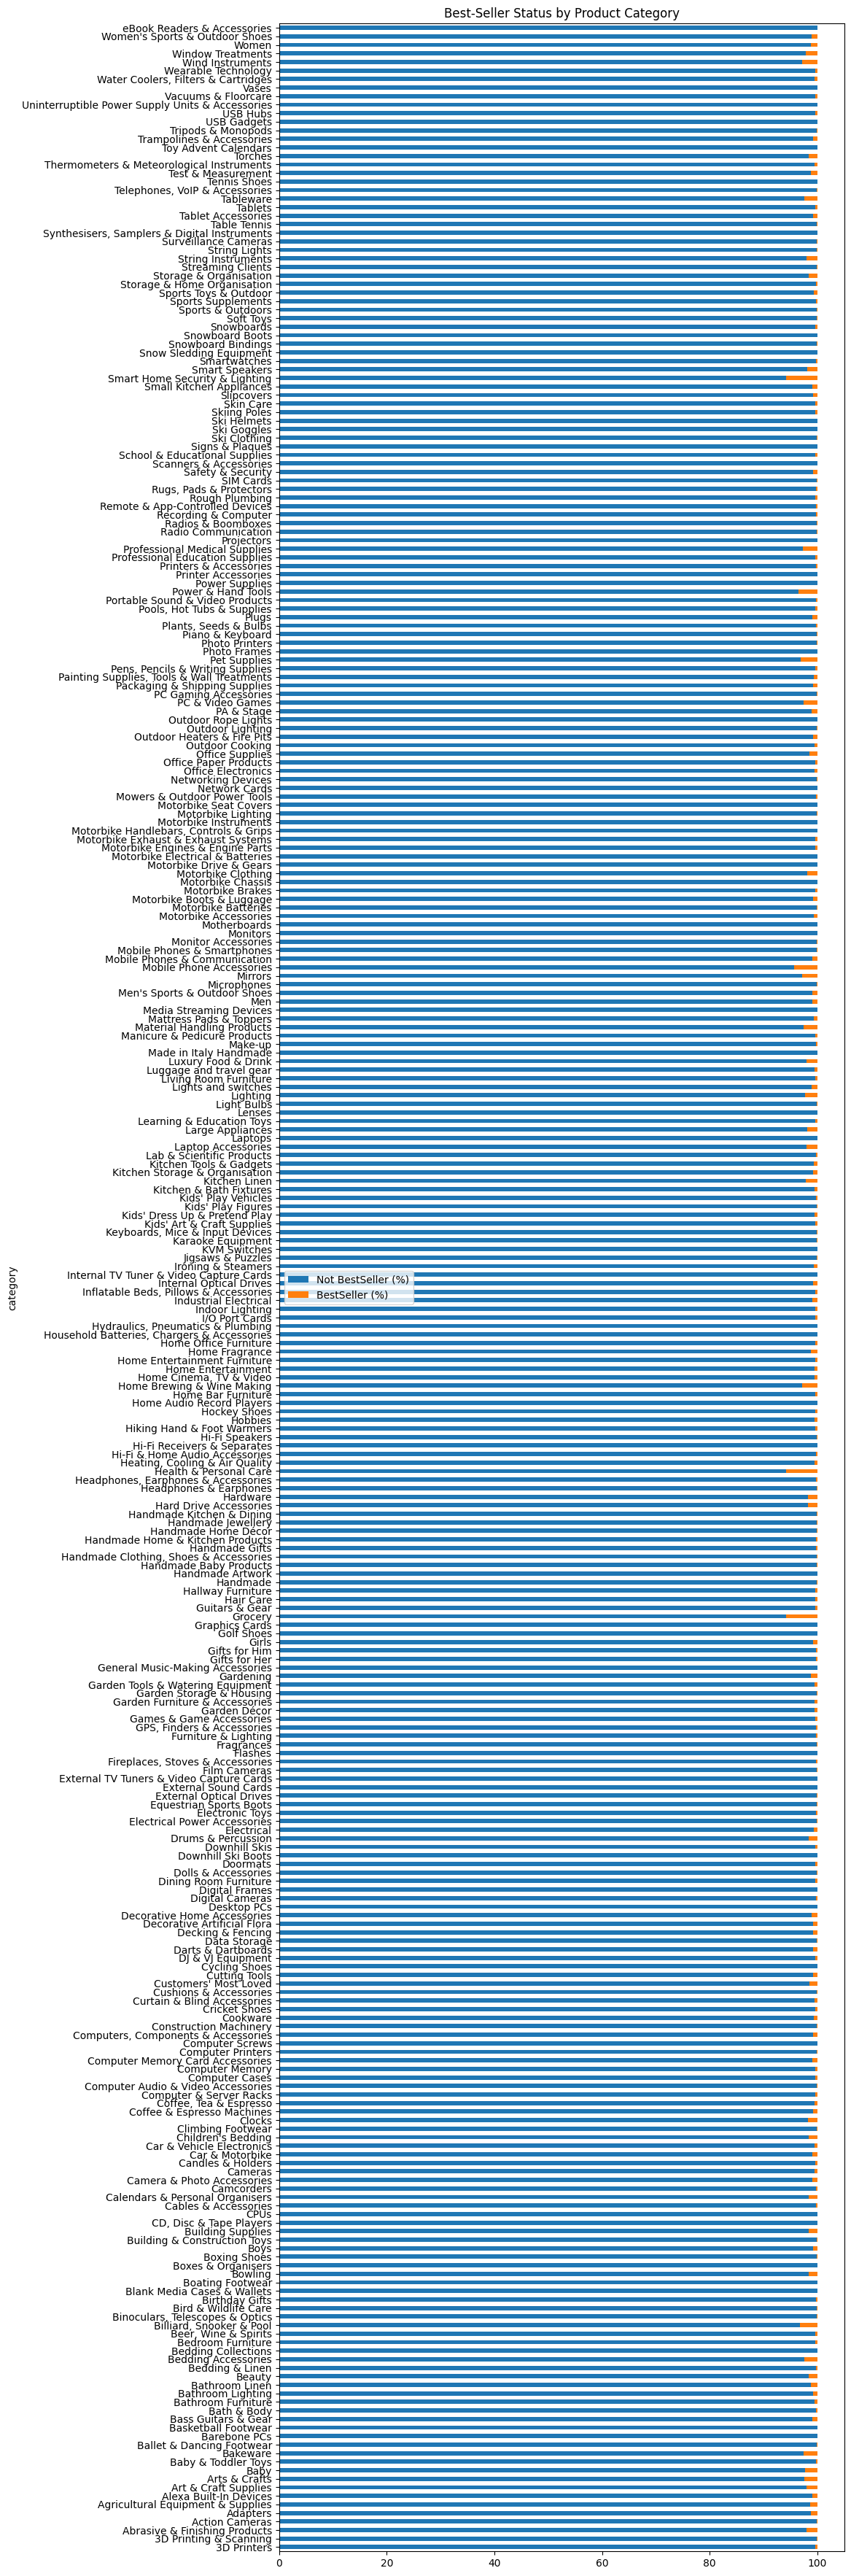

In [15]:
# Visualizations:
# Visualize the relationship between product categories and the best-seller status using a stacked bar chart.
rel_freq.plot(kind="barh", stacked=True,  figsize=(10, 45))
plt.title("Best-Seller Status by Product Category")
# Sort by highest counts of BestSeller
crosstab_result = crosstab_result.sort_values(by='Not BestSeller', ascending=False)
crosstab_result


- The variable category is comprised by many of unique product categories: n = 296. Thus, it may be more readle to plot only the few more represented categories.

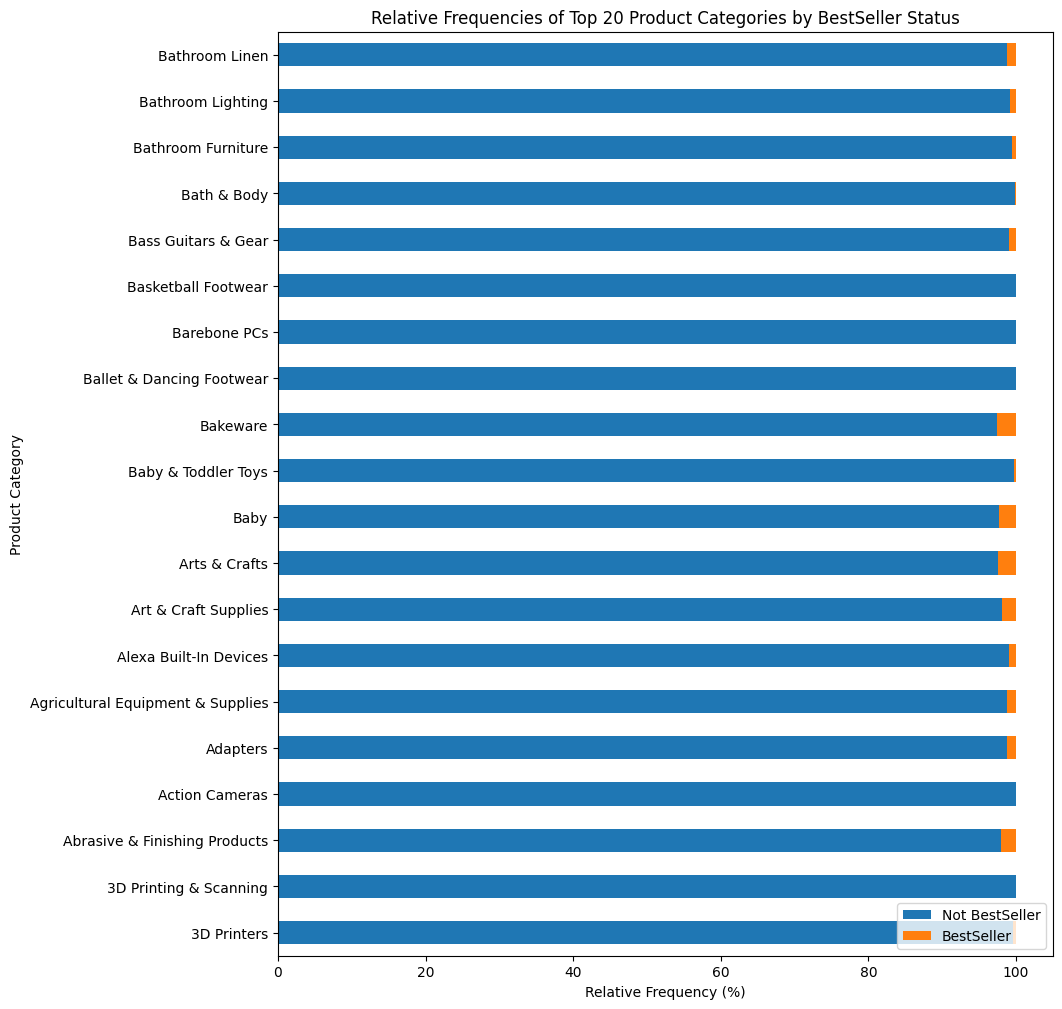

In [16]:
# Select top 20 categories based on total frequency
top_categories = rel_freq.sum(axis=1).sort_values(ascending=False).head(20).index

# Filter the relative frequency table
rel_freq_top = rel_freq.loc[top_categories]

# Plot horizontal stacked bar chart
rel_freq_top.plot(
    kind="barh",
    stacked=True,
    figsize=(10, 12),  # adjust height for readability
    )

plt.xlabel("Relative Frequency (%)")
plt.ylabel("Product Category")
plt.title("Relative Frequencies of Top 20 Product Categories by BestSeller Status")
plt.legend(["Not BestSeller", "BestSeller"], loc="lower right")
plt.show()


In [17]:
# Part 2: Exploring Product Prices and Ratings Across Categories and Brands
# Objective: Investigate how different product categories influence product prices.

# 0. Preliminary Step: Remove outliers in product prices.
# For this purpose, we can use the IQR (Interquartile Range) method.
# Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset.
# The next steps will be done with the dataframe without outliers.
# Hint: you can check the last Check For Understanding at the end of the lesson EDA Bivariate Analysis for a hint on how to do this.

# Calculate qurtiles and IQR
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1

# Calculate whiskers
lower_whisker = Q1 - 1.5 * IQR
upper_whisker = Q3 + 1.5 * IQR

Q1, Q3, IQR, lower_whisker, upper_whisker


(np.float64(9.99),
 np.float64(45.99),
 np.float64(36.0),
 np.float64(-44.01),
 np.float64(99.99000000000001))

In [18]:
# Filter out outliers
df_no_price_outliers = df[(df['price'] <= upper_whisker) & (df['price'] >= lower_whisker)]
# Display basic information about the dataframe
df_no_price_outliers.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2115963 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 147.3+ MB


- Plotting a violin plot to visualize the distribution of price across different product category

C:\Users\cpall\AppData\Local\Temp\ipykernel_22248\4091711641.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df_top20, x='price', y='category', palette="coolwarm")


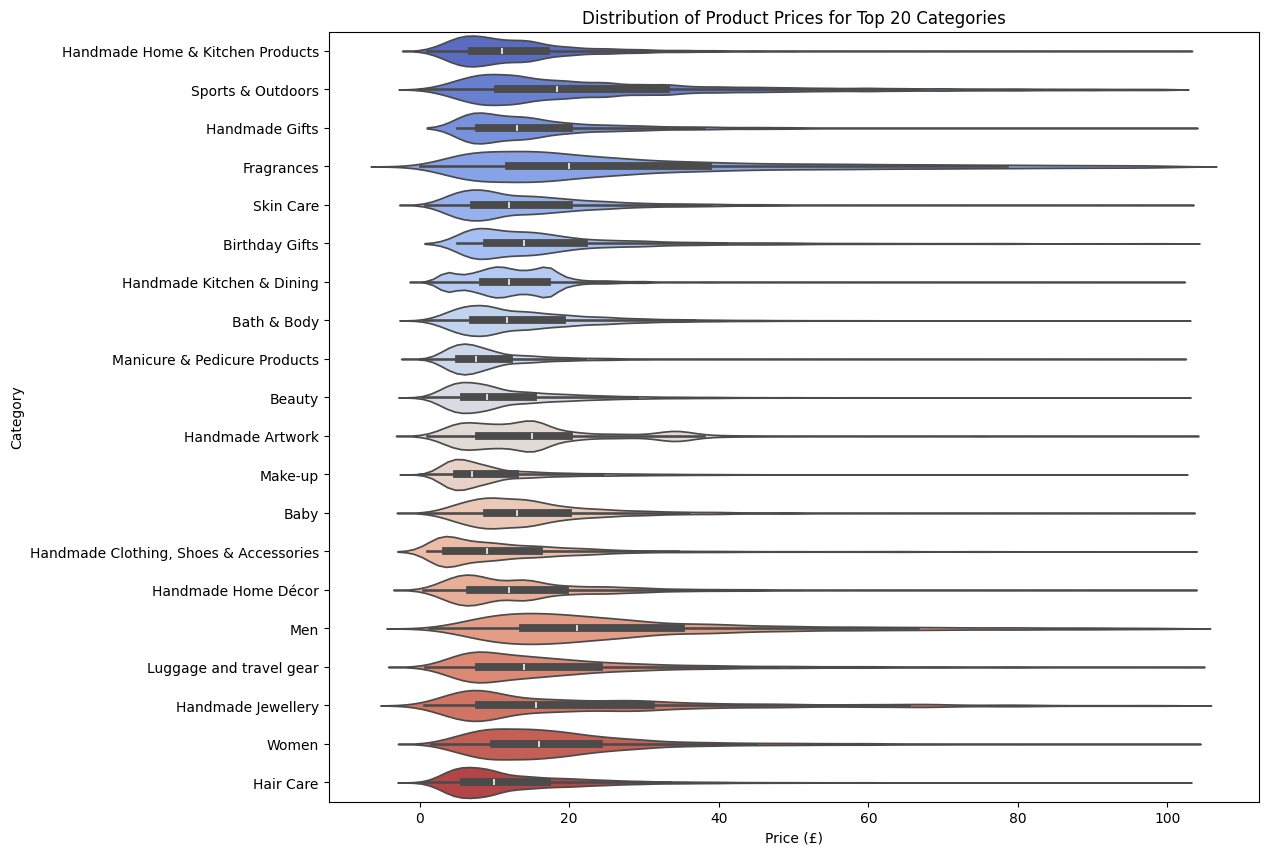

In [19]:
# 1. Violin Plots:

# Use a violin plot to visualize the distribution of price across different product categories.
# Filter out the top 20 categories based on count for better visualization.

import seaborn as sns
import matplotlib.pyplot as plt

# Count products per category
# top_categories = df_no_price_outliers['category'].value_counts().head(20).index

# Filter dataset for top 20 categories
# df_top20 = df_no_price_outliers[df_no_price_outliers['category'].isin(top_categories)]

df_top20 = df_no_price_outliers[df_no_price_outliers['category'].isin(df_no_price_outliers['category'].value_counts().head(20).index)]


# Plot violin plot
plt.figure(figsize=(12, 10))
sns.violinplot(data=df_top20, x='price', y='category', palette="coolwarm")
plt.title("Distribution of Product Prices for Top 20 Categories")
plt.xlabel("Price (£)")
plt.ylabel("Category")
plt.show()


- In the dataset (with outliers excluded), the five product categories with the highest median prices are: Desktop PCs (£74.0), Boxing Shoes (£69.8), Tablets (£69.0), Graphics Cards (£68.5), and Motherboards (£67.9).

In [21]:
# Which product category tends to have the highest median price? Don't filter here by top categories.
median_price = df_no_price_outliers.groupby('category')['price'].median().sort_values(ascending=False)
median_price

category
Desktop PCs              74.00
Boxing Shoes             69.79
Tablets                  69.00
Graphics Cards           68.54
Motherboards             67.92
                         ...  
Adapters                  7.05
Make-up                   7.00
Signs & Plaques           6.99
Arts & Crafts             5.99
Office Paper Products     4.37
Name: price, Length: 296, dtype: float64

- In the dataset (with outliers excluded), the two product categories with the highest average prices are Sports & Outdoor and Birthday Gifts. 
- The categories with the highest average prices differ from those with the highest median price, highlighting the influence of extreme values on the mean.

C:\Users\cpall\AppData\Local\Temp\ipykernel_22248\3615160894.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=avg_price_top10.values, y=avg_price_top10.index, palette="viridis")


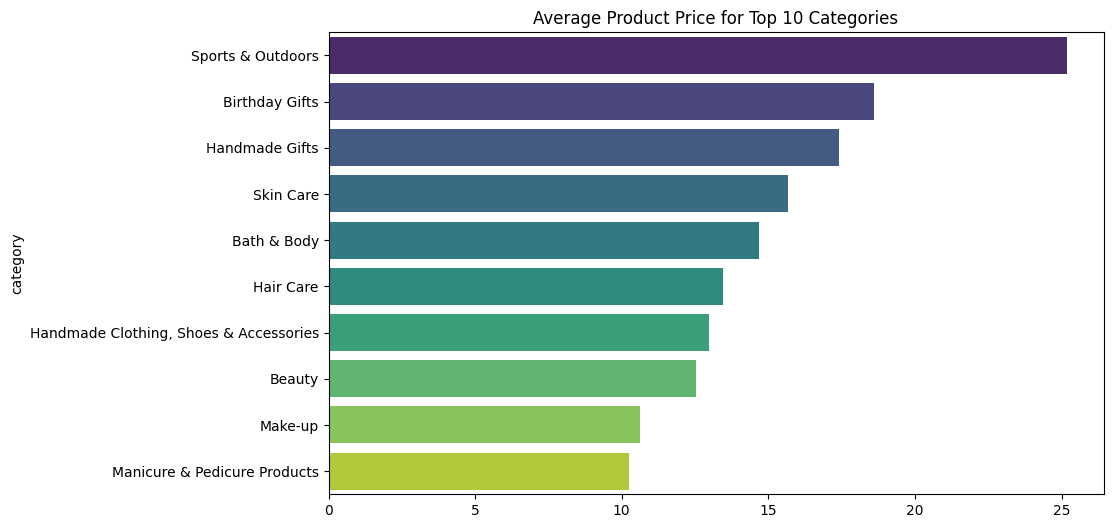

In [22]:
# 2. Bar Charts:
# Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
# Which product category commands the highest average price? Don't filter here by top categories.

# Top 10 product categories (based on count)
top_10_categories = df_no_price_outliers['category'].value_counts().head(10).index

# Calculate average price for top 10 categories
avg_price_top10 = df_no_price_outliers[df_no_price_outliers['category'].isin(top_10_categories)].groupby('category')['price'].mean().sort_values(ascending=False)
# Plot bar chart
plt.figure(figsize=(10, 6))
sns.barplot(x=avg_price_top10.values, y=avg_price_top10.index, palette="viridis")
plt.title("Average Product Price for Top 10 Categories")

# Absolute frequencies (counts)
counts = pd.crosstab(df['category'], df['isBestSeller'])



C:\Users\cpall\AppData\Local\Temp\ipykernel_22248\3918399847.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_top10, x='category', y='stars', palette="coolwarm")


Text(0, 0.5, 'Median Ratings (Stars)')

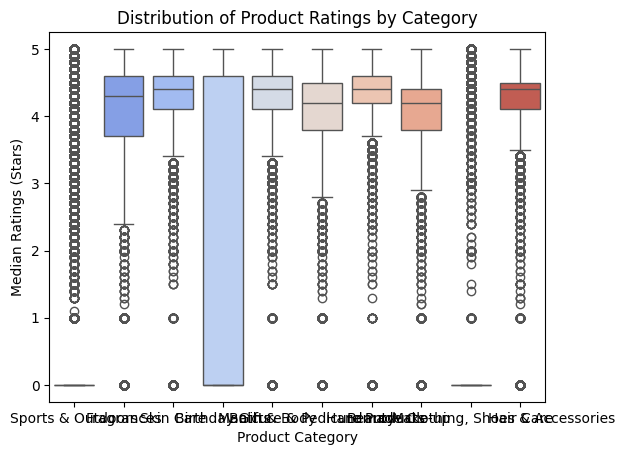

In [23]:
# 3. Box Plots:
# Visualize the distribution of product ratings based on their category using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
# Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

# 0. Preliminary Step: Remove outliers in product ratings.

# Calculate qurtiles and IQR
Q1_rating = df['stars'].quantile(0.25)
Q3_rating = df['stars'].quantile(0.75)
IQR_rating = Q3_rating - Q1_rating

# Calculate whiskers
lower_whisker_rating = Q1_rating - 1.5 * IQR_rating
upper_whisker_rating = Q3_rating + 1.5 * IQR_rating

Q1_rating, Q3_rating, IQR_rating, lower_whisker_rating, upper_whisker_rating

df_no_rating_outliers = df[(df['stars'] <= upper_whisker_rating) & (df['stars'] >= lower_whisker_rating)]

# Top 10 product categories (based on count)
top_10_categories = df_no_rating_outliers['category'].value_counts().head(10).index


# Top 10 product categories (based on count)
df_top10 = df_no_rating_outliers[df_no_rating_outliers['category'].isin(top_10_categories)]

# Box plot of rating for each category, using the "coolwarm" color palette
sns.boxplot(data=df_top10, x='category', y='stars', palette="coolwarm")
plt.title("Distribution of Product Ratings by Category")
plt.xlabel("Product Category")
plt.ylabel("Median Ratings (Stars)")

C:\Users\cpall\AppData\Local\Temp\ipykernel_22248\3692318405.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_top10, x='category', y='stars', palette="coolwarm")


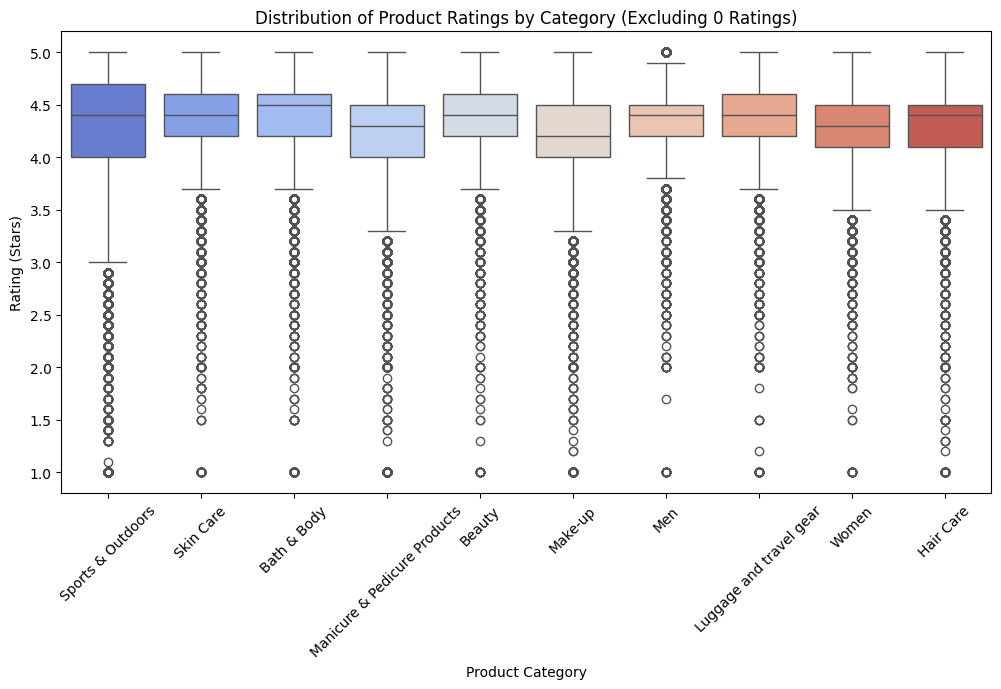

In [24]:
# Filter out 0 ratings
df_no_zero_ratings = df[df['stars'] > 0]

# Top 10 product categories (based on count)
top_10_categories = df_no_zero_ratings['category'].value_counts().head(10).index

# Filter dataset for top 10 categories
df_top10 = df_no_zero_ratings[df_no_zero_ratings['category'].isin(top_10_categories)]

# Box plot of rating for each top category
plt.figure(figsize=(12,6))
sns.boxplot(data=df_top10, x='category', y='stars', palette="coolwarm")
plt.title("Distribution of Product Ratings by Category (Excluding 0 Ratings)")
plt.xlabel("Product Category")
plt.ylabel("Rating (Stars)")
plt.xticks(rotation=45)
plt.show()


C:\Users\cpall\AppData\Local\Temp\ipykernel_22248\3494601909.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_top10_clean, x='category', y='stars', palette="coolwarm")


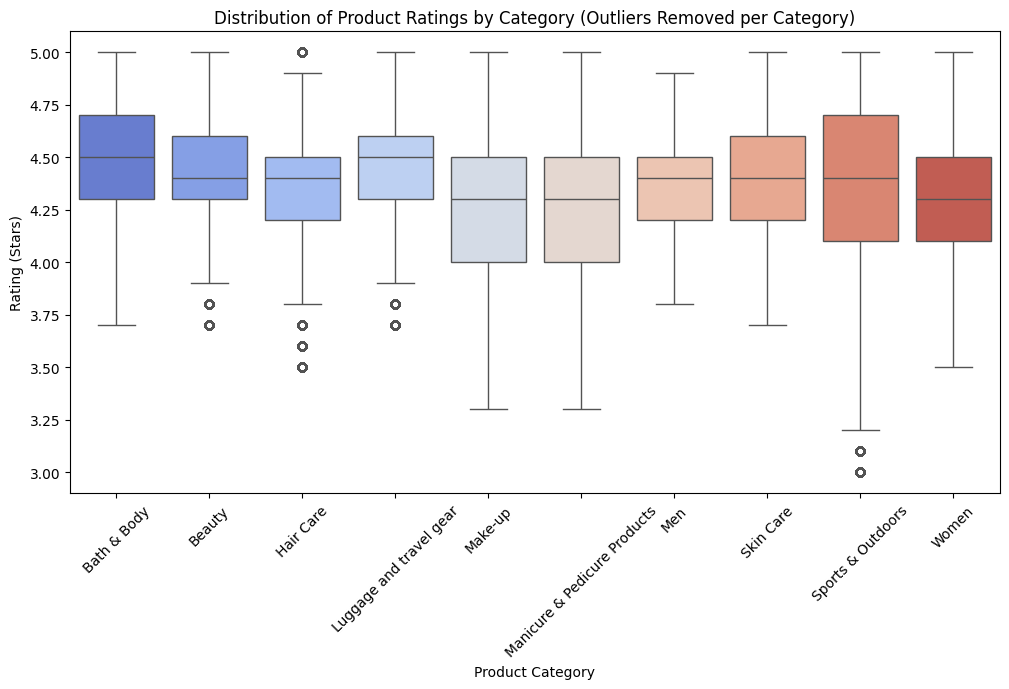

In [25]:
# Function to remove outliers per category
def remove_outliers_per_category(df, col='stars'):
    filtered = pd.DataFrame()
    for cat, group in df.groupby('category'):
        Q1 = group[col].quantile(0.25)
        Q3 = group[col].quantile(0.75)
        IQR = Q3 - Q1
        lower = Q1 - 1.5*IQR
        upper = Q3 + 1.5*IQR
        filtered = pd.concat([filtered, group[(group[col] >= lower) & (group[col] <= upper)]])
    return filtered

df_top10_clean = remove_outliers_per_category(df_top10, col='stars')

plt.figure(figsize=(12,6))
sns.boxplot(data=df_top10_clean, x='category', y='stars', palette="coolwarm")
plt.title("Distribution of Product Ratings by Category (Outliers Removed per Category)")
plt.xlabel("Product Category")
plt.ylabel("Rating (Stars)")
plt.xticks(rotation=45)
plt.show()


- The highest median rating is observed for the category Computer Memory, with a median of 4.7 stars. This is followed by seven categories, each with a median rating of 4.6 stars: CPUs, Building & Construction Toys, Laptop Accessories, Hobbies, Kids' Play Figures, Beer, Wine & Spirits, Office Paper Products, and Luxury Food & Drink.

In [26]:
# Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

# Calculate median rating per category
median_rating_per_category = df.groupby('category')['stars'].median().sort_values(ascending=False)

# Display top categories by median rating
print("Top categories by median rating:")
print(median_rating_per_category.head(10))


Top categories by median rating:
category
Computer Memory                 4.7
CPUs                            4.6
Building & Construction Toys    4.6
Laptop Accessories              4.6
Hobbies                         4.6
Kids' Play Figures              4.6
Beer, Wine & Spirits            4.6
Office Paper Products           4.6
Luxury Food & Drink             4.6
Children's Bedding              4.5
Name: stars, dtype: float64


- The Pearson correlation coefficient (r = –0.005) indicates a very weak, negligible, negative relationship between product price and rating. Although the p-value suggests that this relationship is statistically significant, this significance is likely due to the large sample size rather than a meaningful association between the variables.

In [ ]:
# Part 3: Investigating the Interplay Between Product Prices and Ratings
# Objective: Analyze how product ratings (stars) correlate with product prices.

# Correlation Coefficients:

# Calculate the correlation coefficient between price and stars.
# Is there a significant correlation between product price and its rating?


# Filter out 0 ratings
df_no_zero_ratings = df[df['stars'] > 0]

# Check normality of distributions
import scipy.stats as stats
import numpy as np
from scipy.stats import kstest, norm

# Standardize the data (mean=0, std=1) for K-S test against normal distribution (this is the formula for calculating z-scores)
df_no_zero_ratings_std = (df_no_zero_ratings['stars'] - df_no_zero_ratings['stars'].mean()) / df_no_zero_ratings['stars'].std()

# Kolmogorov-Smirnov test
ks_stat, ks_pvalue = kstest(df_no_zero_ratings_std, 'norm')

print(f"KS statistic: {ks_stat:.4f}")
print(f"P-value: {ks_pvalue:.4f}")

if ks_pvalue < 0.05:
    print("The distribution is significantly different from normal (reject H0).")
else:
    print("The distribution does not significantly differ from normal (fail to reject H0).")


KS statistic: 0.1541
P-value: 0.0000
The distribution is significantly different from normal (reject H0).


In [ ]:
# Alternative used for data standardization:
# automatic calculation of z-scores: z-score (or standard score) tells how far a data point is from the mean in terms of standard deviations)

# Import zscore
from scipy.stats import kstest, zscore

# Standardize the 'stars' column
df_no_zero_ratings_std = zscore(df_no_zero_ratings['stars'])

# Kolmogorov-Smirnov test
ks_stat, ks_pvalue = kstest(df_no_zero_ratings_std, 'norm')

print(f"KS statistic: {ks_stat:.4f}")
print(f"P-value: {ks_pvalue:.4f}")

KS statistic: 0.1541
P-value: 0.0000


- Since the stars distribution is not normal, it is used the Spearman’s rank correlation non-parametric test.
- It measures the monotonic relationship between two variables without assuming normality.
- The Spearman correlation coefficient is very small (0.02), indicating little if any correlation.

In [42]:
# Spearman correlation
from scipy.stats import spearmanr

corr_coeff, p_value = spearmanr(df_no_zero_ratings["price"], df_no_zero_ratings["stars"])


print(f"Spearman correlation coefficient: {corr_coeff:.4f}")
print(f"p-value: {ks_pvalue:.4f}")

# Interpret significance
alpha = 0.05
if p_value < alpha:
    print("The correlation is statistically significant.")
else:
    print("The correlation is not statistically significant.")



Spearman correlation coefficient: 0.0200
p-value: 0.0000
The correlation is statistically significant.


- The scatter plot confirms the previous observation of a negligible correlation between product rating and price, suggesting that rating is not a strong predictor of price.
- In fact, the regression line is almost flat, lying near the x-axis; for each stars value, prices vary widely, indicating no clear linear trend.
- The variability of prices increases slightly for higher-rated products

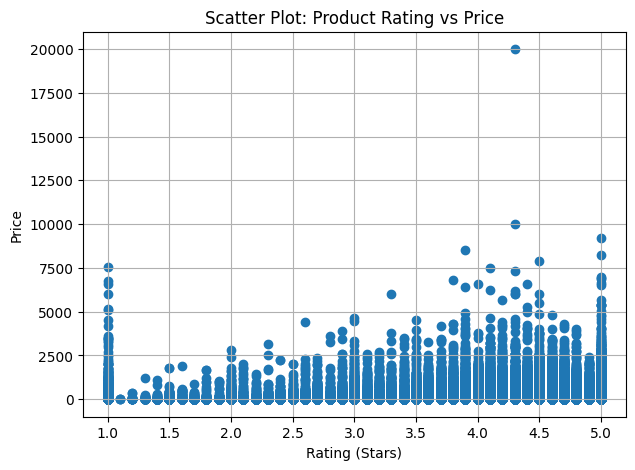

In [ ]:
# Visualizations:
# 1. Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

# 1. Scatter Plot: Rating vs Price
plt.figure(figsize=(7, 5))
plt.scatter(df_no_zero_ratings['stars'], df_no_zero_ratings['price'])
plt.title('Scatter Plot: Product Rating vs Price')
plt.xlabel('Rating (Stars)')
plt.ylabel('Price')
plt.grid(True)
plt.show()

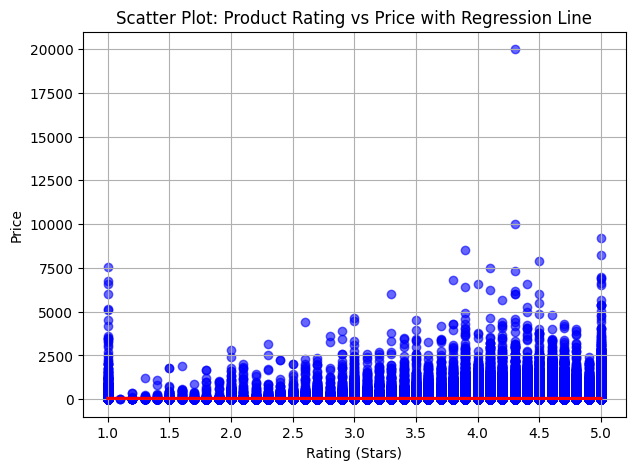

In [33]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

# Scatter plot with regression line
sns.regplot(
    x='stars', 
    y='price', 
    data=df_no_zero_ratings, 
    scatter_kws={'color': 'blue', 'alpha': 0.6}, 
    line_kws={'color': 'red'}
)

plt.title('Scatter Plot: Product Rating vs Price with Regression Line')
plt.xlabel('Rating (Stars)')
plt.ylabel('Price')
plt.grid(True)
plt.show()


- Each cell in the heatmap shows the Pearson correlation coefficient between two numerical variables, representing their pairwise linear association.
- In this dataset, most correlations are negligible or weak, indicating that the quantitative var do not exhibit strong linear relationships with one another.

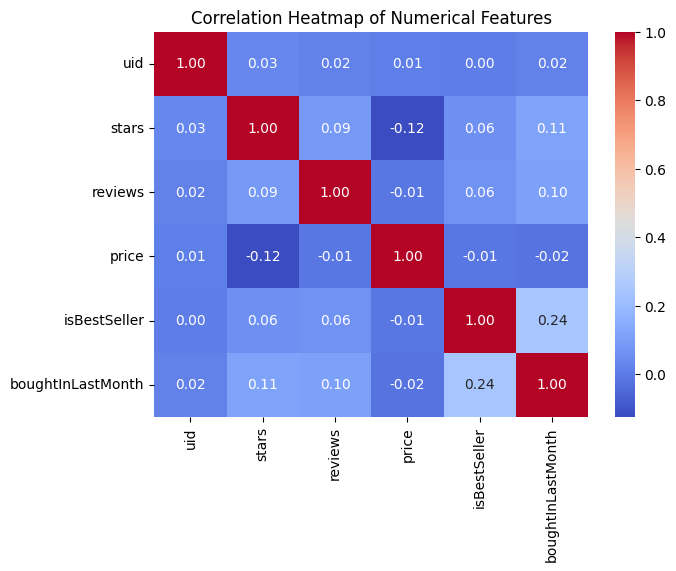

In [ ]:
# Visualizations:
# 2. Use a correlation heatmap to visualize correlations between all numerical variables.

plt.figure(figsize=(7, 5))
corr = df.corr(numeric_only=True)
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap of Numerical Features')
plt.show()


- The Q-Q plot indicates that product prices do not follow a normal distribution.

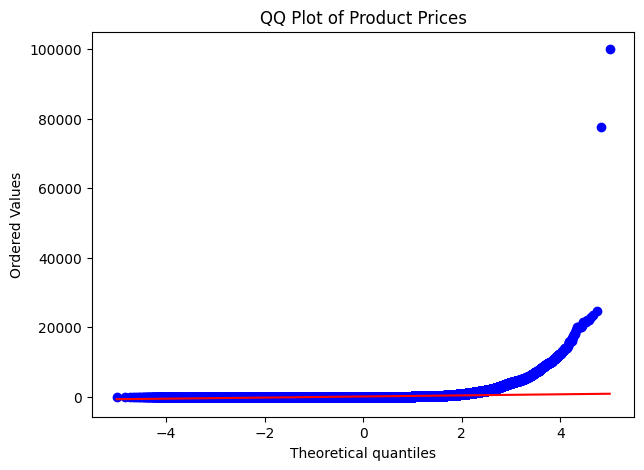

In [ ]:
# # Visualizations:
# 3. Examine if product prices typically follow a normal distribution using a QQ plot.
plt.figure(figsize=(7, 5))
stats.probplot(df['price'], dist="norm", plot=plt)
plt.title('QQ Plot of Product Prices')
plt.show()